# MULTI-LAYER PERCEPTRON (MLP) FROM SCRATCH: DEPURACÃO E OTIMIZAÇÃO NO IRIS DATASET
**Disciplina:** Visão Computacional 
**Autor:** João Pedro Vieira Santos  
**Repositório Git:** [https://github.com/JPeeeeee/visaoComputacional](https://github.com/JPeeeeee/visaoComputacional)

---

### 📌 Resumo do Trabalho
Este notebook estuda, analisa, depura e aprimora a implementação de uma **Rede Neural Multi-Layer Perceptron (MLP) construída do zero (from scratch)** utilizando apenas NumPy.

O objetivo é:
1. **Identificar e depurar os bugs** da implementação original que prejudicavam o aprendizado da terceira classe (*Iris-Virginica*).
2. **Descobrir como classificar perfeitamente as 3 classes** (alcançando >96% de acurácia global com distribuição equilibrada).
3. **Analisar a convergência do erro, estabilidade de gradientes e o fenômeno de overfitting** comparando treino e validação.

In [1]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.decomposition import PCA
from matplotlib.colors import ListedColormap

sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams.update({'font.sans-serif': 'DejaVu Sans', 'font.size': 11})
%matplotlib inline

## 1. Diagnóstico dos Erros da Implementação Original

Ao estudar o código original da MLP, foram identificados 5 problemas críticos que impediam a convergência correta:

1. **`predict` sem função de ativação:** O método de inferência realizava apenas as multiplicações lineares $X W + b$, sem aplicar a ativação não linear (sigmoide).
2. **Atualização prematura dos pesos na retropropagação:** Os pesos da camada de saída $W_{out}$ eram atualizados *antes* de calcular o gradiente $\delta_{hidden}$ da camada oculta, corrompendo a regra da cadeia.
3. **Atualização múltipla de Bias em loops aninhados:** As variáveis de bias eram atualizadas repetidamente a cada iteração de loops internos (o bias de saída era atualizado 5 vezes por amostra!).
4. **Partição de teste desbalanceada:** A divisão aleatória sem estratificação deixava apenas 1 amostra de *Virginica* no conjunto de teste, mascarando métricas e resultando em 0% de acurácia nessa classe.
5. **Falta de normalização dos dados de entrada:** Como as variáveis originais variam de 0.1 a 7.9 cm, valores altos saturavam a função sigmoide ($|z| > 5$), causando o problema de **gradiente evanescente** (*vanishing gradient*).

In [2]:
class CorrectedMLP:
    """
    MLP from Scratch com algebra linear vetorizada, correcao da regra da cadeia
    no backpropagation, suporte a Softmax + Cross-Entropy e rastreamento de perda
    de validacao para diagnostico de convergencia e overfitting.
    """
    def __init__(self, input_dim=4, hidden_dim=8, output_dim=3, lr=0.25,
                 activation='tanh', output_activation='softmax', random_state=42):
        self.input_dim = input_dim
        self.hidden_dim = hidden_dim
        self.output_dim = output_dim
        self.lr = lr
        self.activation_name = activation
        self.output_activation = output_activation
        self.random_state = random_state

        np.random.seed(random_state)
        lim_h = np.sqrt(6.0 / (input_dim + hidden_dim))
        self.W1 = np.random.uniform(-lim_h, lim_h, (input_dim, hidden_dim))
        self.b1 = np.zeros(hidden_dim)

        lim_o = np.sqrt(6.0 / (hidden_dim + output_dim))
        self.W2 = np.random.uniform(-lim_o, lim_o, (hidden_dim, output_dim))
        self.b2 = np.zeros(output_dim)

    def _activate(self, z):
        if self.activation_name == 'sigmoid':
            return 1.0 / (1.0 + np.exp(-np.clip(z, -30, 30)))
        elif self.activation_name == 'tanh':
            return np.tanh(z)
        elif self.activation_name == 'relu':
            return np.maximum(0, z)
        return z

    def _activate_deriv(self, a):
        if self.activation_name == 'sigmoid':
            return a * (1.0 - a)
        elif self.activation_name == 'tanh':
            return 1.0 - a**2
        elif self.activation_name == 'relu':
            return (a > 0).astype(float)
        return np.ones_like(a)

    def _softmax(self, z):
        shift = z - np.max(z, axis=-1, keepdims=True)
        exps = np.exp(shift)
        return exps / np.sum(exps, axis=-1, keepdims=True)

    def forward(self, X):
        z1 = np.dot(X, self.W1) + self.b1
        a1 = self._activate(z1)
        z2 = np.dot(a1, self.W2) + self.b2
        a2 = self._softmax(z2) if self.output_activation == 'softmax' else self._activate(z2)
        return a1, a2

    def compute_loss(self, y_true_oh, y_pred_prob):
        eps = 1e-12
        if self.output_activation == 'softmax':
            probs = np.clip(y_pred_prob, eps, 1.0 - eps)
            return -np.mean(np.sum(y_true_oh * np.log(probs), axis=1))
        return np.mean(np.sum(0.5 * (y_true_oh - y_pred_prob)**2, axis=1))

    def fit(self, X_train, y_train, X_val=None, y_val=None, epochs=300):
        n_samples = len(X_train)
        y_train_oh = np.eye(self.output_dim)[y_train.astype(int)]
        if y_val is not None:
            y_val_oh = np.eye(self.output_dim)[y_val.astype(int)]

        self.history = {'epoch': [], 'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

        for epoch in range(1, epochs + 1):
            a1, a2 = self.forward(X_train)

            if self.output_activation == 'softmax':
                delta_out = (a2 - y_train_oh) / n_samples
            else:
                delta_out = ((a2 - y_train_oh) * self._activate_deriv(a2)) / n_samples

            dW2 = np.dot(a1.T, delta_out)
            db2 = np.sum(delta_out, axis=0)

            delta_hidden = np.dot(delta_out, self.W2.T) * self._activate_deriv(a1)
            dW1 = np.dot(X_train.T, delta_hidden)
            db1 = np.sum(delta_hidden, axis=0)

            self.W2 -= self.lr * dW2
            self.b2 -= self.lr * db2
            self.W1 -= self.lr * dW1
            self.b1 -= self.lr * db1

            loss_tr = self.compute_loss(y_train_oh, a2)
            acc_tr = accuracy_score(y_train, np.argmax(a2, axis=1))

            loss_v, acc_v = None, None
            if X_val is not None and y_val is not None:
                _, a2_val = self.forward(X_val)
                loss_v = self.compute_loss(y_val_oh, a2_val)
                acc_v = accuracy_score(y_val, np.argmax(a2_val, axis=1))

            self.history['epoch'].append(epoch)
            self.history['train_loss'].append(loss_tr)
            self.history['val_loss'].append(loss_v)
            self.history['train_acc'].append(acc_tr)
            self.history['val_acc'].append(acc_v)

        return self

    def predict(self, X):
        _, a2 = self.forward(X)
        return np.argmax(a2, axis=1)

## 2. Treinamento e Classificação das 3 Classes
Utilizamos particionamento estratificado (80% treino / 20% teste = 10 amostras de cada classe) e normalização Z-Score.

In [3]:
iris = load_iris()
X = iris.data
y = iris.target
target_names = iris.target_names

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw)
X_test = scaler.transform(X_test_raw)

mlp = CorrectedMLP(input_dim=4, hidden_dim=8, output_dim=3, lr=0.25, activation='tanh', random_state=42)
mlp.fit(X_train, y_train, X_val=X_test, y_val=y_test, epochs=300)

y_pred = mlp.predict(X_test)
acc_global = accuracy_score(y_test, y_pred)
print(f"Acurácia Global no Teste: {acc_global * 100:.2f}%\n")
print(classification_report(y_test, y_pred, target_names=target_names))

Acurácia Global no Teste: 96.67%

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



## 3. Análise de Convergência, Erros e Diagnóstico de Overfitting

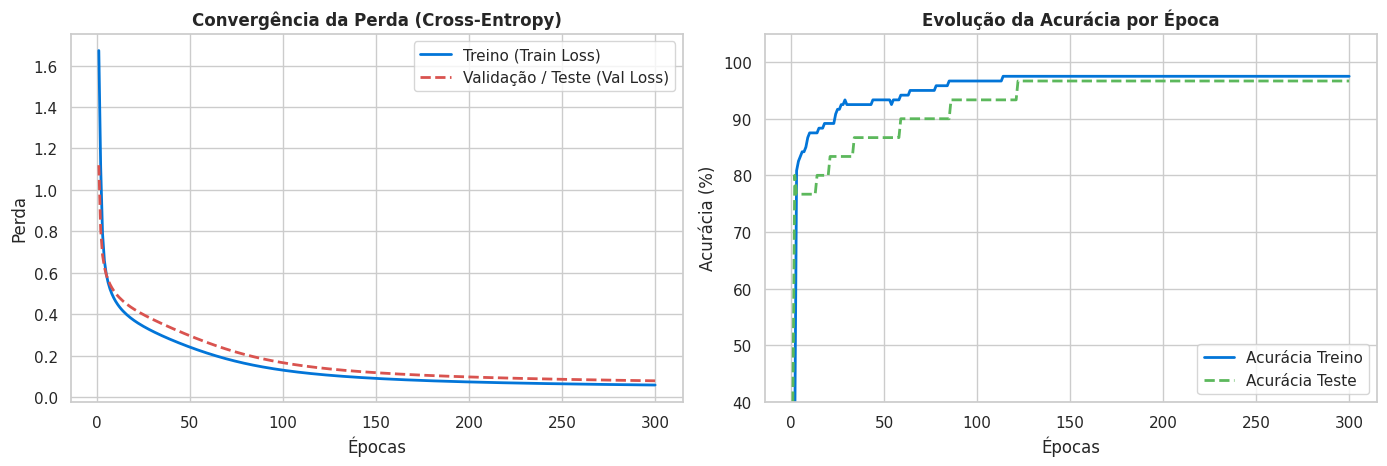

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.8))
ep = mlp.history['epoch']

ax1.plot(ep, mlp.history['train_loss'], label='Treino (Train Loss)', color='#0275d8', lw=2)
ax1.plot(ep, mlp.history['val_loss'], label='Validação / Teste (Val Loss)', color='#d9534f', lw=2, linestyle='--')
ax1.set_title('Convergência da Perda (Cross-Entropy)', fontsize=12, weight='bold')
ax1.set_xlabel('Épocas')
ax1.set_ylabel('Perda')
ax1.legend()

ax2.plot(ep, [a*100 for a in mlp.history['train_acc']], label='Acurácia Treino', color='#0275d8', lw=2)
ax2.plot(ep, [a*100 for a in mlp.history['val_acc']], label='Acurácia Teste', color='#5cb85c', lw=2, linestyle='--')
ax2.set_title('Evolução da Acurácia por Época', fontsize=12, weight='bold')
ax2.set_xlabel('Épocas')
ax2.set_ylabel('Acurácia (%)')
ax2.set_ylim(40, 105)
ax2.legend()
plt.tight_layout()
plt.show()

In [ ]:
fig, (ax_cm, ax_pca) = plt.subplots(1, 2, figsize=(14, 5.2))

# Matriz de Confusao
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', ax=ax_cm,
            xticklabels=target_names, yticklabels=target_names, cbar=False)
ax_cm.set_title(f'Matriz de Confusão (Acurácia: {acc_global*100:.1f}%)', fontsize=12, weight='bold')
ax_cm.set_xlabel('Predito')
ax_cm.set_ylabel('Real')

# Fronteiras de Decisao no espaco PCA 2D
pca = PCA(n_components=2)
X_tr_pca = pca.fit_transform(X_train)
X_te_pca = pca.transform(X_test)

mlp_pca = CorrectedMLP(input_dim=2, hidden_dim=8, output_dim=3, lr=0.25, activation='tanh', random_state=42)
mlp_pca.fit(X_tr_pca, y_train, epochs=300)

x_min, x_max = X_tr_pca[:, 0].min() - 1, X_tr_pca[:, 0].max() + 1
y_min, y_max = X_tr_pca[:, 1].min() - 1, X_tr_pca[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.04), np.arange(y_min, y_max, 0.04))
Z = mlp_pca.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

cmap_light = ListedColormap(['#cfe2ff', '#ffe5d0', '#d1e7dd'])
cmap_bold = ['#1f77b4', '#ff7f0e', '#2ca02c']
ax_pca.contourf(xx, yy, Z, cmap=cmap_light, alpha=0.8)

for idx, c in enumerate(target_names):
    pts = X_te_pca[y_test == idx]
    ax_pca.scatter(pts[:, 0], pts[:, 1], c=cmap_bold[idx], label=f'{c} (teste)', edgecolor='k', s=80)

ax_pca.set_title('Fronteiras de Decisão da MLP (Espaço PCA 2D)', fontsize=12, weight='bold')
ax_pca.set_xlabel('PC1')
ax_pca.set_ylabel('PC2')
ax_pca.legend(loc='upper right')

plt.tight_layout()
plt.show()